# Speckle2Self Architecture Comparison
Side-by-side comparison of the first frame per patient across three conditions:

| Column | Description |
|--------|-------------|
| **Raw** | Original ultrasound image (`cropped_pngs3`) |
| **Original arch** | First working run — black spots from clipped activations (`260423-054945`) |
| **Tanh (fixed)** | Proper training with tanh on last decoder layer (`260720-cropped4`, epoch 199) |

In [24]:
import os
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display as ipy_display, Image as IPyImage

In [25]:
# ── Paths ────────────────────────────────────────────────────────────────────
RAW_ROOT    = r"D:\dissertation-results\cropped_pngs3"
FAULTY_ROOT = r"D:\dissertation-results\speckle2self-results\git_inf\260423-054945"
FIXED_ROOT  = r"D:\dissertation-results\speckle2self-results\git_inf\260720-cropped4\epoch199"
OUT_DIR     = r"D:\dissertation-results"

PATIENTS = ["Almeida", "Borges", "Brito"]

def raw_path(patient, stem):
    return os.path.join(RAW_ROOT, patient, "cross-section", f"{stem}.png")

def faulty_path(patient, stem):
    return os.path.join(FAULTY_ROOT, patient.lower(), f"{stem}_denoised.png")

def fixed_path(patient, stem):
    return os.path.join(FIXED_ROOT, patient.lower(), f"{stem}_denoised.png")

def first_stem(patient):
    """Return the stem of the first frame present in all three sources."""
    raw_dir = os.path.join(RAW_ROOT, patient, "cross-section")
    for fname in sorted(os.listdir(raw_dir)):
        if not fname.endswith('.png'):
            continue
        stem = fname[:-4]
        if os.path.exists(faulty_path(patient, stem)) and os.path.exists(fixed_path(patient, stem)):
            return stem
    raise FileNotFoundError(f"No common first frame found for {patient}")

In [26]:
# ── Resolve first frames ──────────────────────────────────────────────────────
stems = {}
for p in PATIENTS:
    stems[p] = first_stem(p)
    print(f"{p}: {stems[p]}")

Almeida: IM-0001-0001_frame_000
Borges: IM-0001-0208_frame_003
Brito: IM-0001-0208_frame_001


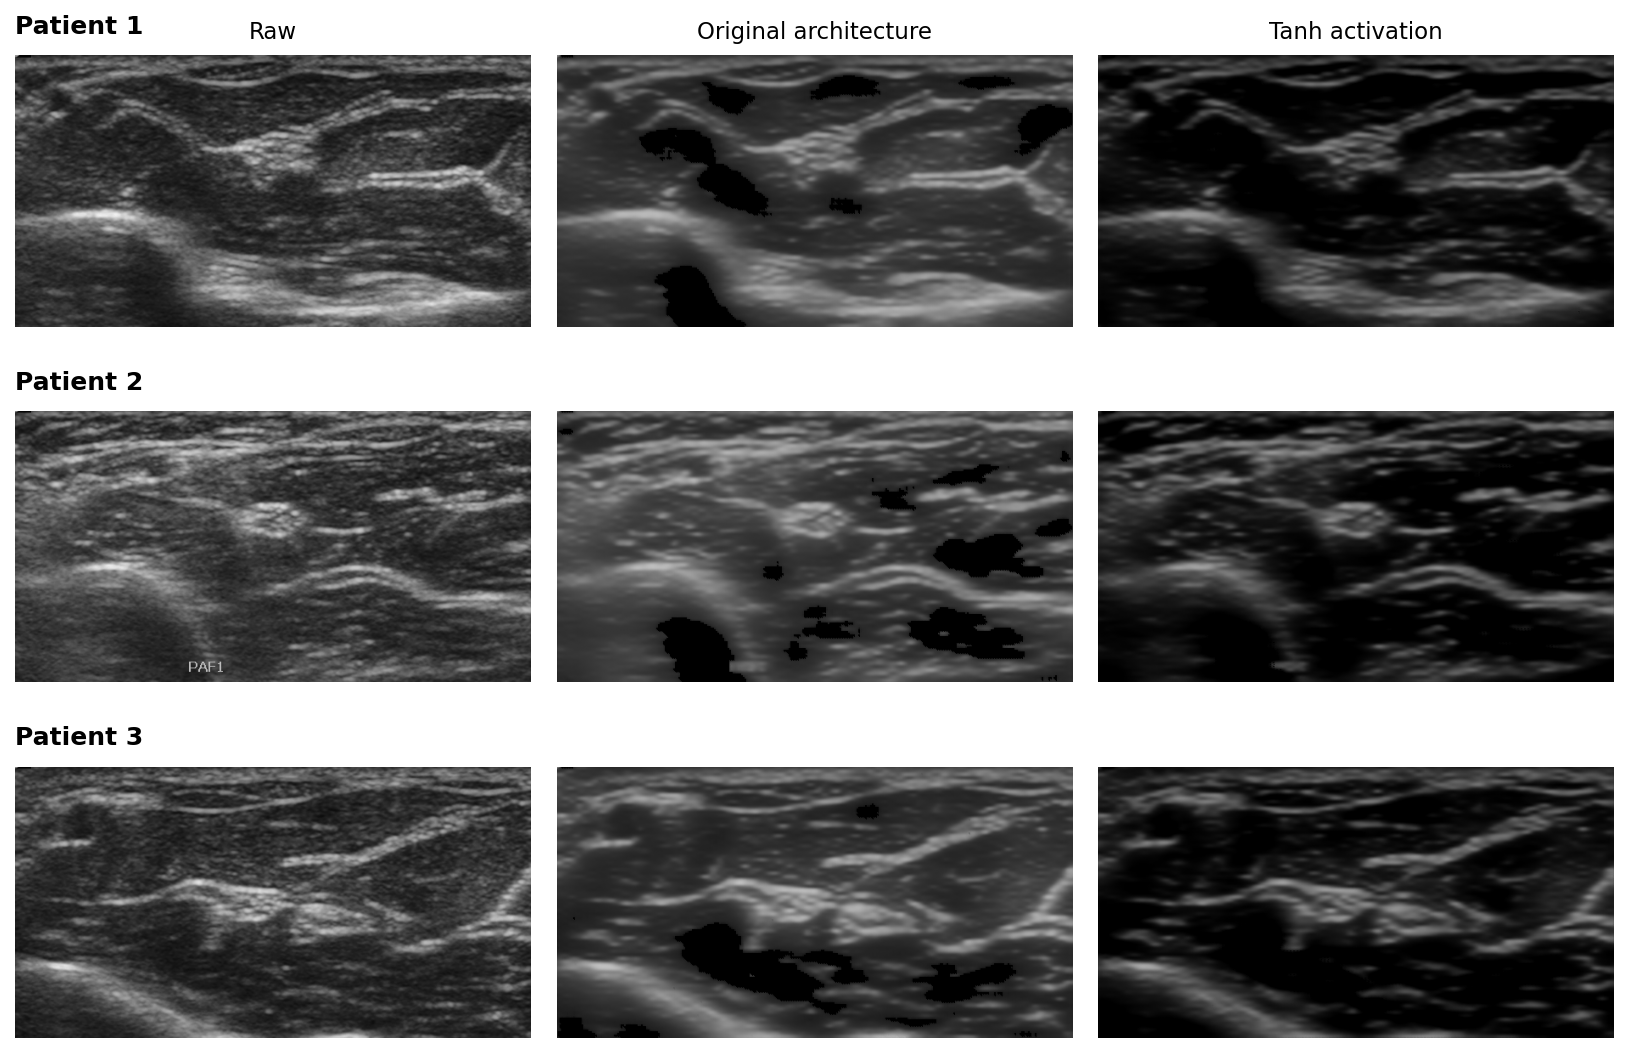

Saved -> D:\dissertation-results\speckle2self_comparison.png


In [27]:
# ── Plot ──────────────────────────────────────────────────────────────────────
def load_gray(path):
    return np.array(Image.open(path).convert('L'))

LABELS     = ["Raw", "Original architecture", "Tanh activation"]
ROW_LABELS = [f"Patient {i+1}" for i in range(len(PATIENTS))]

fig, axes = plt.subplots(len(PATIENTS), 3, figsize=(13, 2.8 * len(PATIENTS)))
plt.subplots_adjust(hspace=0.15, wspace=0.05, top=0.92, left=0.08)

for row, patient in enumerate(PATIENTS):
    stem = stems[patient]
    images = [
        load_gray(raw_path(patient, stem)),
        load_gray(faulty_path(patient, stem)),
        load_gray(fixed_path(patient, stem)),
    ]

    for col, (img, label) in enumerate(zip(images, LABELS)):
        ax = axes[row, col]
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        ax.axis('off')

        # Column headers on first row only
        if row == 0:
            ax.set_title(label, fontsize=11, pad=8)

    # Patient label at 45° above the top-left corner of the row
    axes[row, 0].text(0.0, 1.06, ROW_LABELS[row],
                      transform=axes[row, 0].transAxes,
                      rotation=0, ha='left', va='bottom',
                      fontsize=12, fontweight='bold')

out_path = os.path.join(OUT_DIR, "speckle2self_comparison.png")
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out_path))
print(f"Saved -> {out_path}")

In [28]:
# ── Paths + helpers for Raw vs Denoised figures ───────────────────────────────
import numpy as np

DENOISED_ROOT = r"D:\dissertation-results\speckle2self-results\git_inf\260720-cropped4\epoch199"
RAW_ROOT_RD   = r"D:\dissertation-results\cropped_pngs3"
OUT_DIR_RD    = r"D:\graphs-n-tables\speckle2self"

PATIENTS_RD   = ["Almeida", "Borges", "Brito"]
LABEL_MAP_RD  = {"Almeida": "Patient 1", "Borges": "Patient 2", "Brito": "Patient 3"}

def get_pairs(patient, n=None, seed=42):
    """Return list of (raw_path, denoised_path) for frames present in both dirs."""
    dn_dir  = os.path.join(DENOISED_ROOT, patient.lower())
    raw_dir = os.path.join(RAW_ROOT_RD, patient, "cross-section")
    pairs = []
    for fname in sorted(os.listdir(dn_dir)):
        if not fname.endswith('_denoised.png'):
            continue
        stem  = fname.replace('_denoised.png', '')
        raw_p = os.path.join(raw_dir, f"{stem}.png")
        if os.path.exists(raw_p):
            pairs.append((raw_p, os.path.join(dn_dir, fname)))
    if n is not None and len(pairs) > n:
        rng = np.random.default_rng(seed)
        idx = sorted(rng.choice(len(pairs), n, replace=False))
        pairs = [pairs[i] for i in idx]
    return pairs

for p in PATIENTS_RD:
    print(f"{p}: {len(get_pairs(p))} paired frames")

Almeida: 249 paired frames
Borges: 269 paired frames
Brito: 249 paired frames


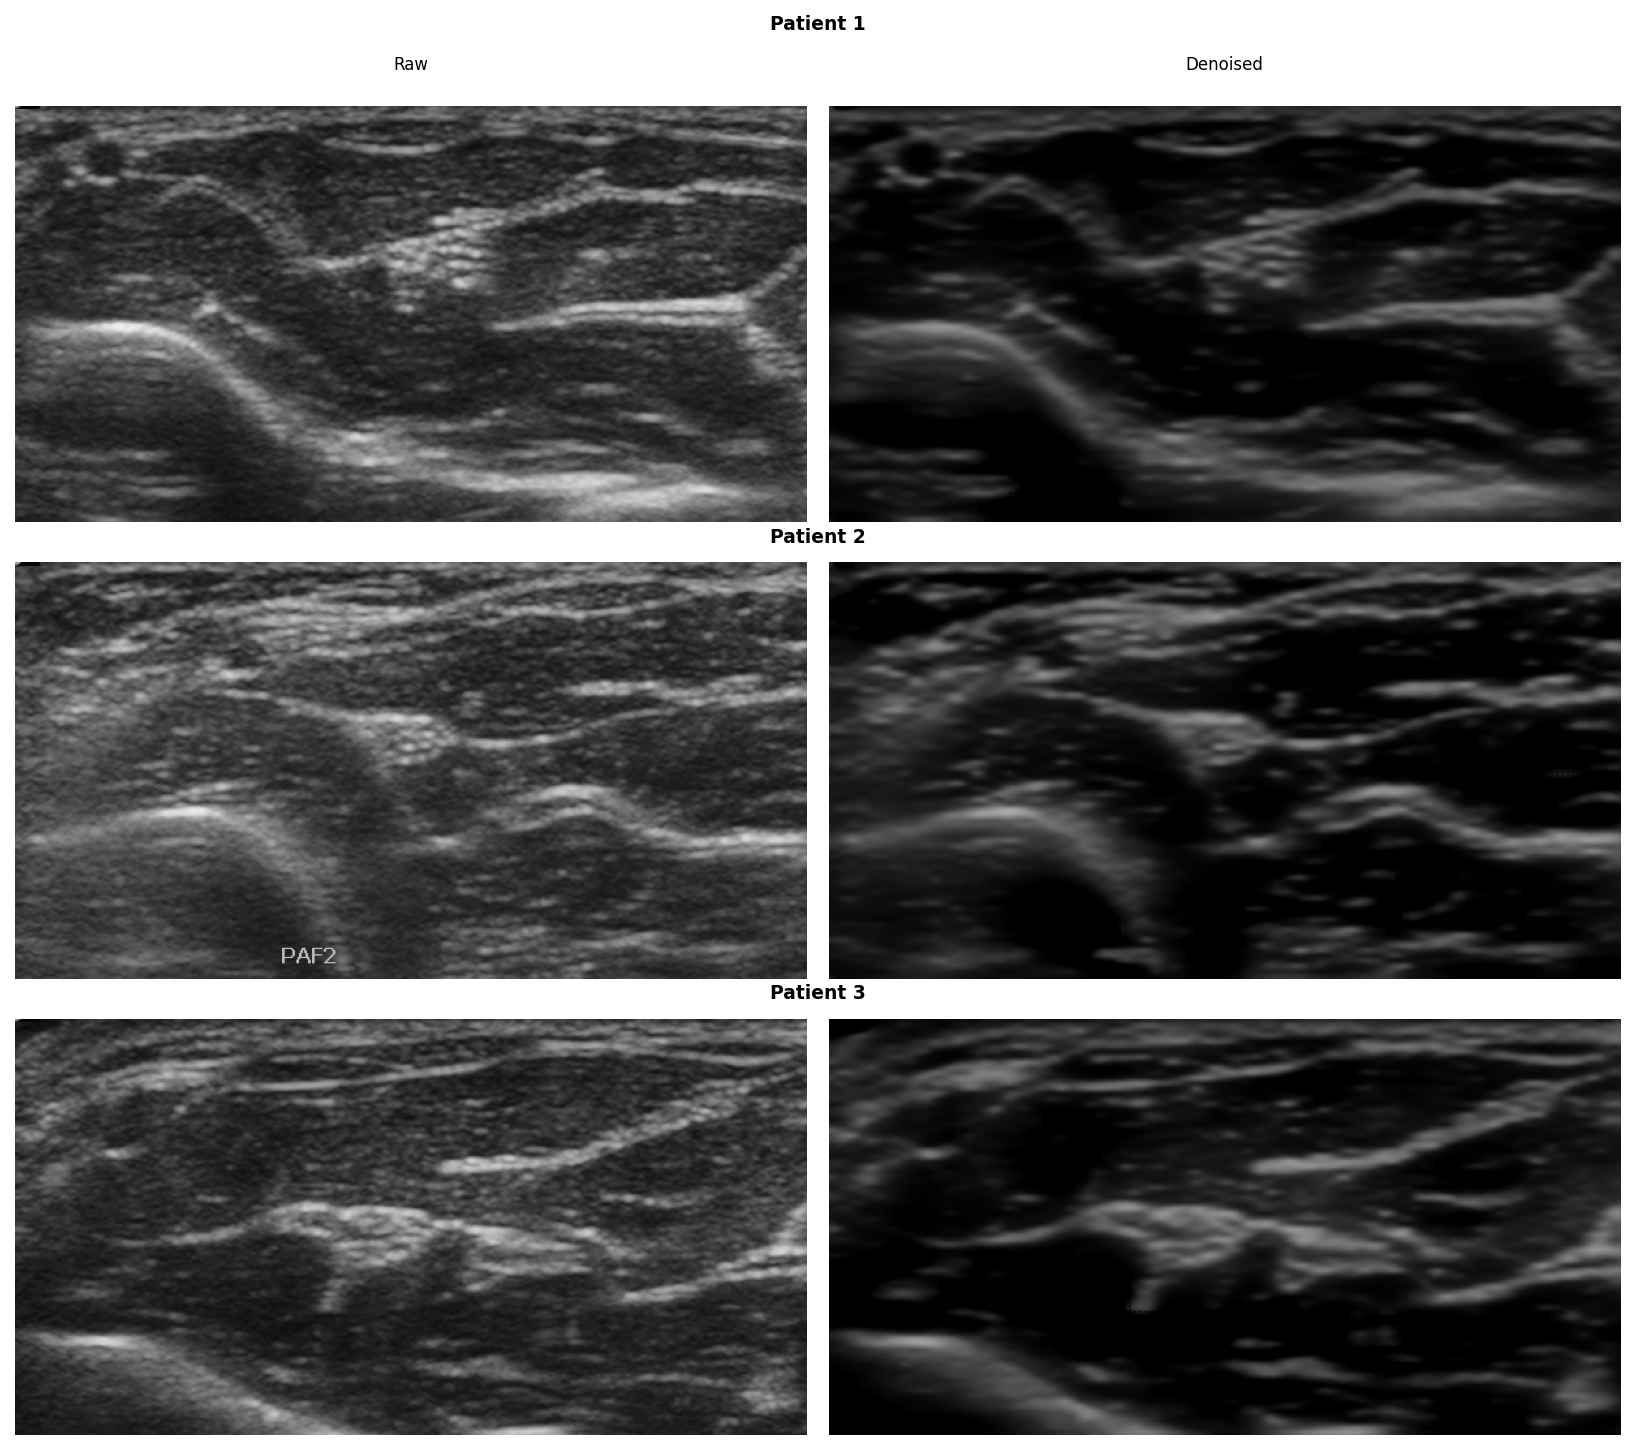

Saved → D:\graphs-n-tables\speckle2self\s2s_denoised_qualitative.png


In [29]:
# ── Mosaic: one frame per patient — Raw vs Denoised ──────────────────────────
fig, axes = plt.subplots(len(PATIENTS_RD), 2, figsize=(11, 3.6 * len(PATIENTS_RD)))

for row, patient in enumerate(PATIENTS_RD):
    raw_p, dn_p = get_pairs(patient, n=1)[0]
    raw_img = np.array(Image.open(raw_p).convert('L'))
    dn_img  = np.array(Image.open(dn_p).convert('L'))
    axes[row, 0].imshow(raw_img, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].axis('off')
    axes[row, 1].imshow(dn_img,  cmap='gray', vmin=0, vmax=255)
    axes[row, 1].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.88)

x_raw = (axes[0, 0].get_position().x0 + axes[0, 0].get_position().x1) / 2
x_dn  = (axes[0, 1].get_position().x0 + axes[0, 1].get_position().x1) / 2
x_mid = (axes[0, 0].get_position().x0 + axes[0, 1].get_position().x1) / 2
y_top = axes[0, 0].get_position().y1

fig.text(x_raw, y_top + 0.020, 'Raw',      ha='center', va='bottom', fontsize=8)
fig.text(x_dn,  y_top + 0.020, 'Denoised', ha='center', va='bottom', fontsize=8)

for row, patient in enumerate(PATIENTS_RD):
    label   = LABEL_MAP_RD[patient]
    y_top_r = axes[row, 0].get_position().y1
    y_label = y_top_r + 0.045 if row == 0 else y_top_r + 0.010
    fig.text(x_mid, y_label, label, ha='center', va='bottom', fontsize=9, fontweight='bold')

out_path = os.path.join(OUT_DIR_RD, 's2s_denoised_qualitative.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out_path))
print(f'Saved → {out_path}')

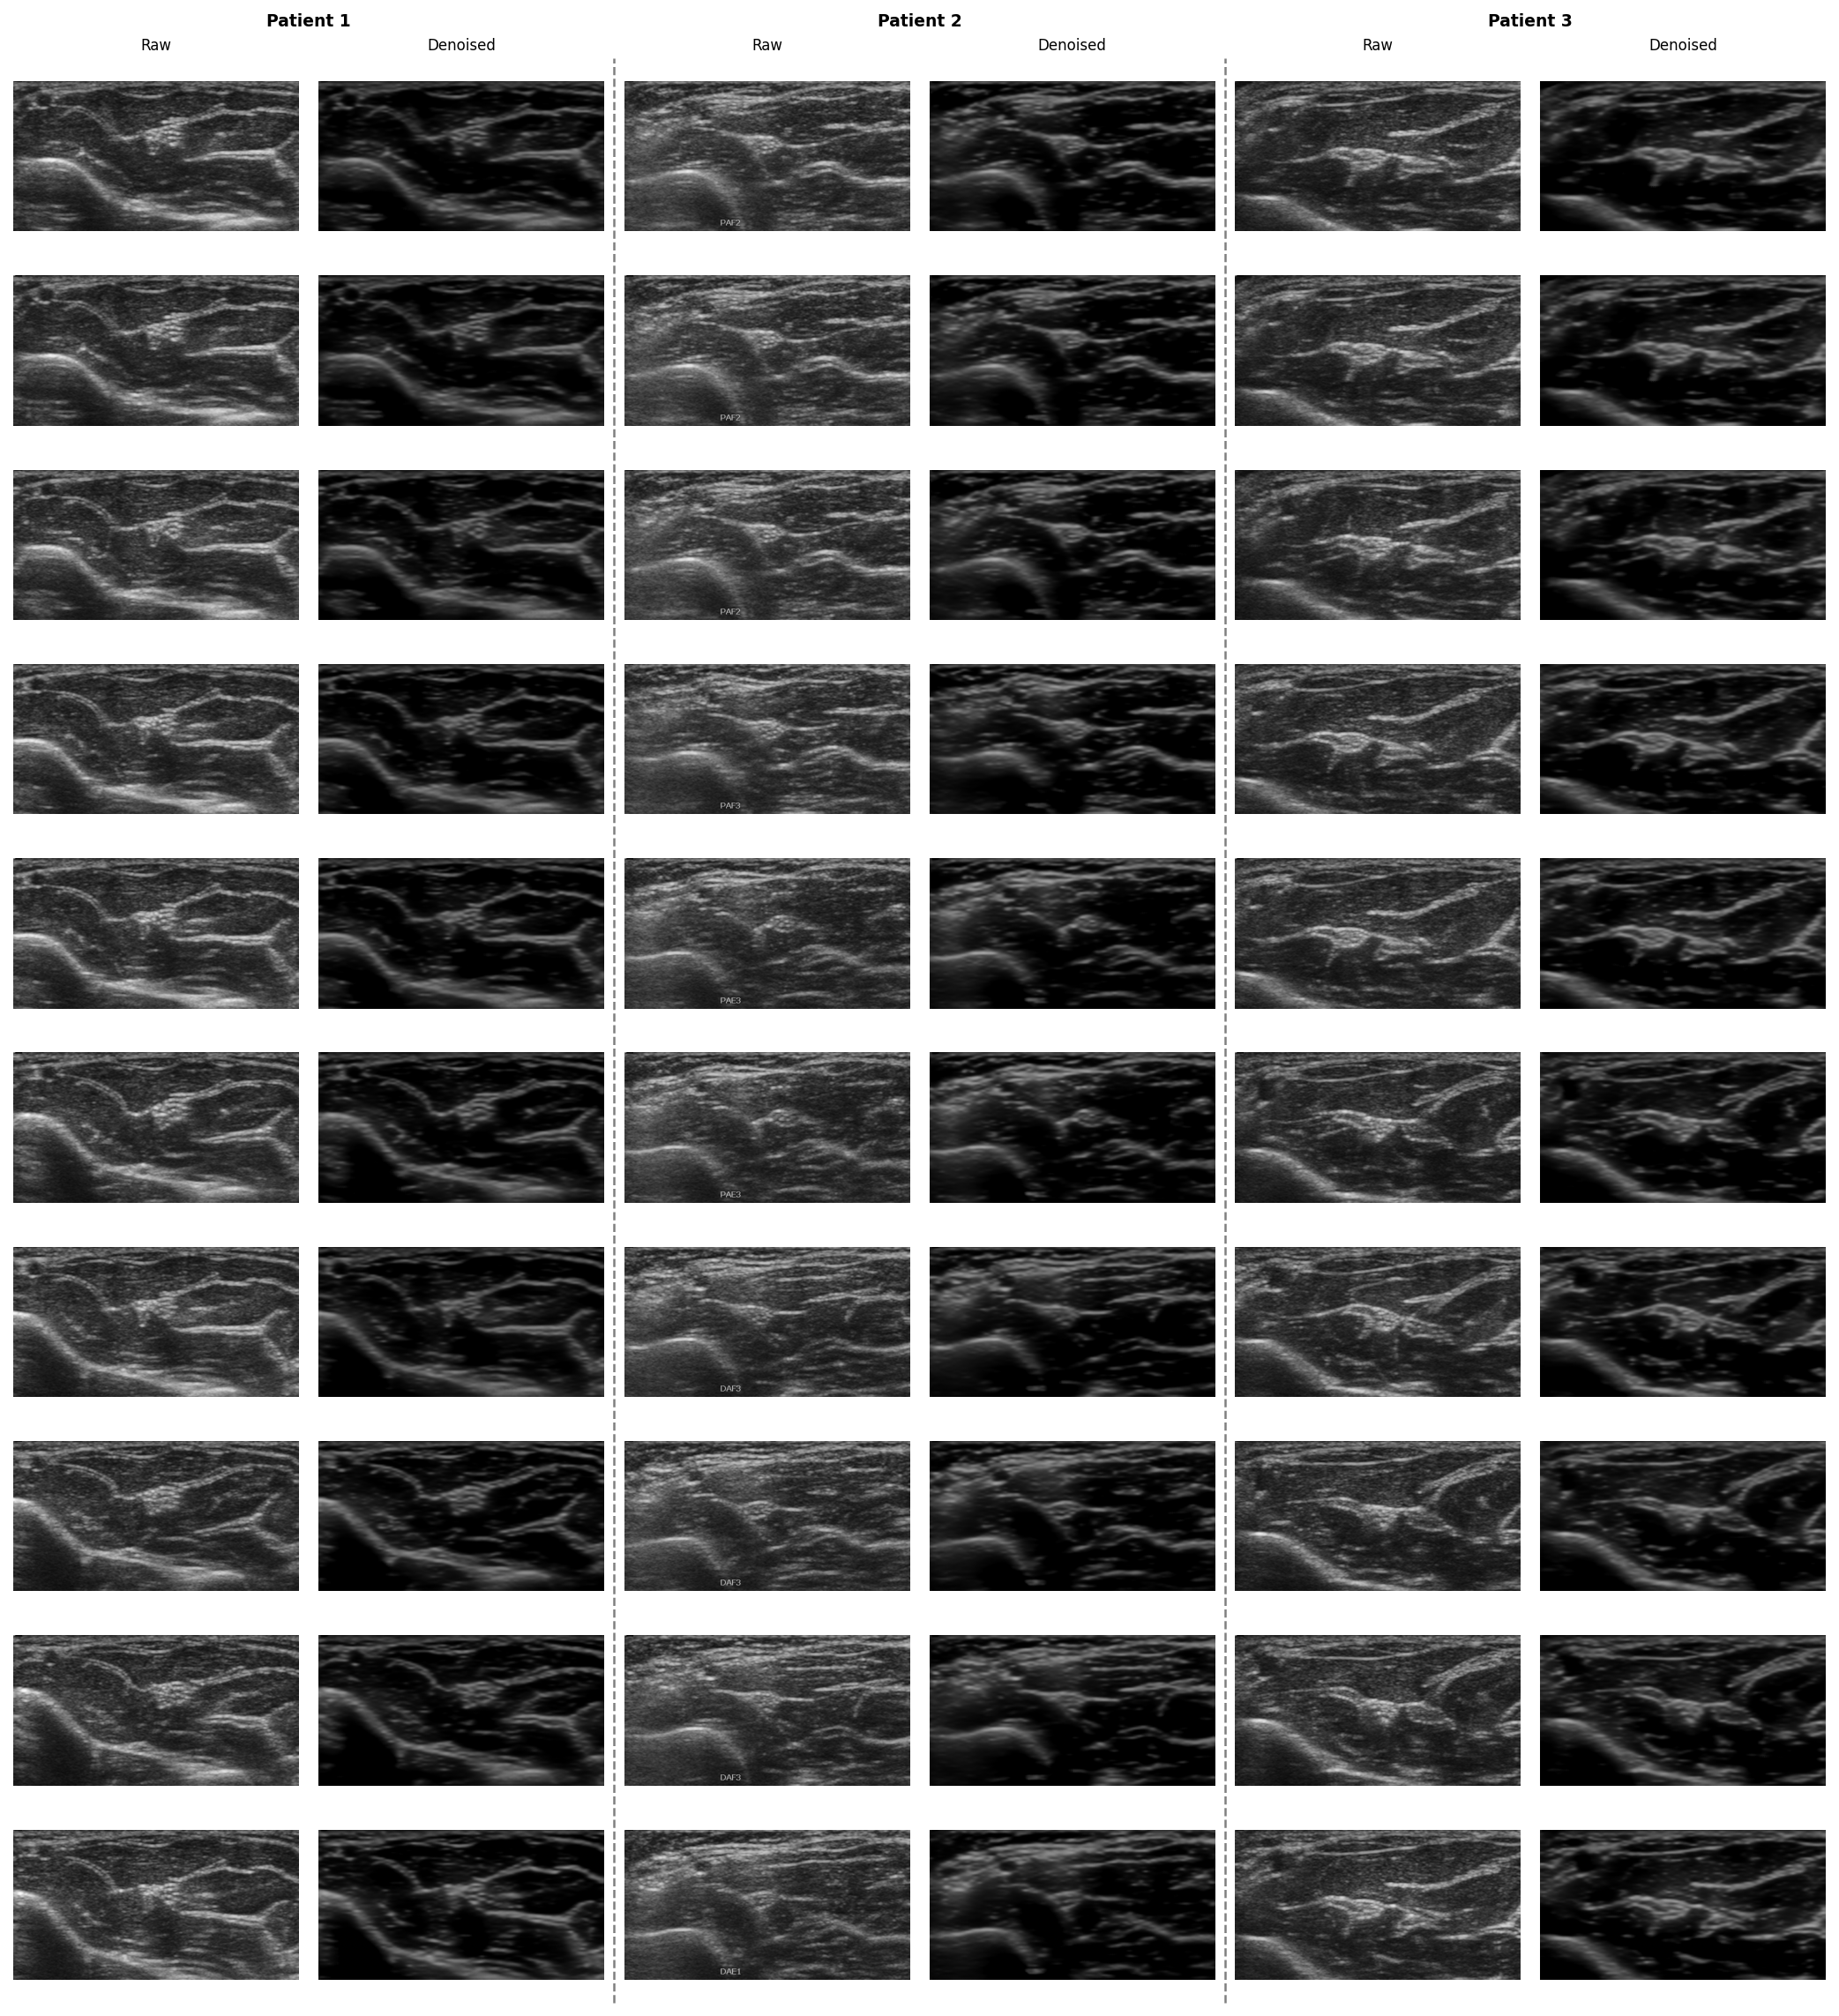

Saved → D:\graphs-n-tables\speckle2self\s2s_denoised_supplementary.png


In [30]:
# ── Supplementary grid: 10 frames × 3 patients — Raw vs Denoised ─────────────
from matplotlib.lines import Line2D

N_FRAMES = 10
SEED     = 42

fig, axes = plt.subplots(N_FRAMES, len(PATIENTS_RD) * 2, figsize=(14, 1.5 * N_FRAMES))

for col_pair, patient in enumerate(PATIENTS_RD):
    pairs   = get_pairs(patient, n=N_FRAMES, seed=SEED)
    col_raw = col_pair * 2
    col_dn  = col_pair * 2 + 1

    for row, (raw_p, dn_p) in enumerate(pairs):
        raw_img = np.array(Image.open(raw_p).convert('L'))
        dn_img  = np.array(Image.open(dn_p).convert('L'))
        axes[row, col_raw].imshow(raw_img, cmap='gray', vmin=0, vmax=255)
        axes[row, col_raw].axis('off')
        axes[row, col_dn].imshow(dn_img,   cmap='gray', vmin=0, vmax=255)
        axes[row, col_dn].axis('off')

plt.tight_layout()

y_top     = axes[0, 0].get_position().y1
y_headers = y_top + 0.014
y_patient = y_top + 0.026

for col_pair, patient in enumerate(PATIENTS_RD):
    label   = LABEL_MAP_RD[patient]
    col_raw = col_pair * 2
    col_dn  = col_pair * 2 + 1

    x_raw  = (axes[0, col_raw].get_position().x0 + axes[0, col_raw].get_position().x1) / 2
    x_dn   = (axes[0, col_dn].get_position().x0  + axes[0, col_dn].get_position().x1)  / 2
    x_mid  = (axes[0, col_raw].get_position().x0 + axes[0, col_dn].get_position().x1)  / 2

    fig.text(x_mid,  y_patient,  label,      ha='center', va='bottom', fontsize=9, fontweight='bold')
    fig.text(x_raw,  y_headers,  'Raw',      ha='center', va='bottom', fontsize=8)
    fig.text(x_dn,   y_headers,  'Denoised', ha='center', va='bottom', fontsize=8)

for sep_col in [1, 3]:
    x_left  = axes[0, sep_col].get_position().x1
    x_right = axes[0, sep_col + 1].get_position().x0
    x_sep   = (x_left + x_right) / 2
    fig.add_artist(Line2D([x_sep, x_sep], [0.01, 0.99],
                          transform=fig.transFigure,
                          color='gray', linewidth=1.2, linestyle='--'))

out_path = os.path.join(OUT_DIR_RD, 's2s_denoised_supplementary.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out_path))
print(f'Saved → {out_path}')

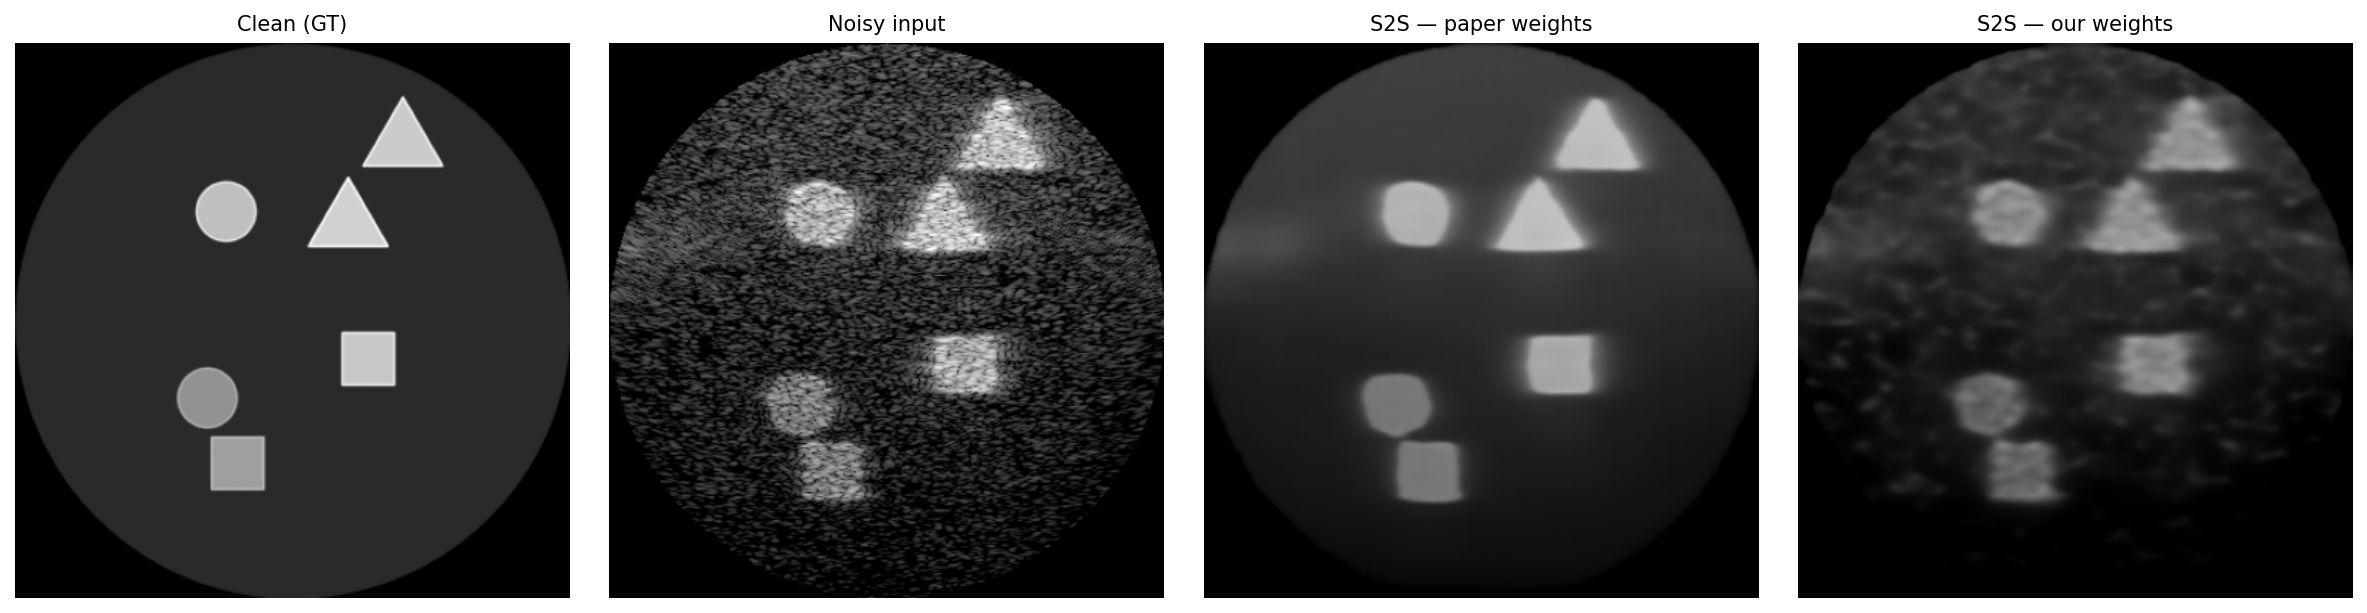

Saved → D:\graphs-n-tables\speckle2self\s2s_sii_comparison.png


In [31]:
# ── S-II single-frame comparison: clean / noisy / paper S2S / our S2S ─────────
def lin_norm(img):
    mn, mx = img.min(), img.max()
    return (img - mn) / (mx - mn + 1e-8)

SII_DATA    = r"D:\dissertation-results\s2s_data\simulator\SII\test_data.npy"
SII_PAPER   = r"D:\dissertation-results\s2s_data\simulator\SII\outputs_paper_SII.npy"
SII_OURS    = r"D:\dissertation-results\s2s_eval\outputs_SII.npy"
FRAME_IDX   = 0   # change to inspect a different frame

data        = np.load(SII_DATA)
noisy       = lin_norm(data[FRAME_IDX, 0])
clean       = lin_norm(data[FRAME_IDX, 1])
dn_paper    = np.load(SII_PAPER)[FRAME_IDX]
dn_ours     = np.load(SII_OURS)[FRAME_IDX]

panels  = [clean, noisy, dn_paper, dn_ours]
titles  = ['Clean (GT)', 'Noisy input', 'S2S — paper weights', 'S2S — our weights']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes, panels, titles):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.axis('off')

fig.tight_layout()
out_path = os.path.join(OUT_DIR_RD, 's2s_sii_comparison.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out_path))
print(f'Saved → {out_path}')

In [ ]:
# ── S-II supplementary grid: 10 frames × 4 panels ────────────────────────────
N_FRAMES  = 10
SEED      = 42

rng       = np.random.default_rng(SEED)
n_total   = np.load(SII_DATA).shape[0]
indices   = sorted(rng.choice(n_total, N_FRAMES, replace=False))

all_data   = np.load(SII_DATA)
all_paper  = np.load(SII_PAPER)
all_ours   = np.load(SII_OURS)

col_titles = ['Clean (GT)', 'Noisy input', 'S2S — paper weights', 'S2S — our weights']

fig, axes = plt.subplots(N_FRAMES, 4, figsize=(14, 1.5 * N_FRAMES))

for row, idx in enumerate(indices):
    panels = [
        lin_norm(all_data[idx, 1]),
        lin_norm(all_data[idx, 0]),
        all_paper[idx],
        all_ours[idx],
    ]
    for col, img in enumerate(panels):
        axes[row, col].imshow(img, cmap='gray', vmin=0, vmax=1)
        axes[row, col].axis('off')

plt.tight_layout()
plt.subplots_adjust(wspace=0.02, hspace=0.02)

y_top = axes[0, 0].get_position().y1
for col, title in enumerate(col_titles):
    x_mid = (axes[0, col].get_position().x0 + axes[0, col].get_position().x1) / 2
    fig.text(x_mid, y_top + 0.014, title, ha='center', va='bottom', fontsize=9)

out_path = os.path.join(OUT_DIR_RD, 's2s_sii_supplementary.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out_path))
print(f'Saved → {out_path}')